# Комплексный анализ результатов онлайн-олимпиады для школьников

---

* **Автор:** Кислицына Милослава
* **Дата:** Октябрь 2026 г.
* **Стек технологий:** Python, pandas, NumPy, matplotlib, seaborn

---

### Цели и задачи проекта
1. **Аудит и валидация:** выявление дубликатов, аномалий логирования и пропусков в данных.
2. **Предобработка:** очистка (дубликаты, пропуски, регионы, аномальные сессии)
3. **Исследовательский анализ (EDA):**
   * Анализ аудитории (регионы, классы, устройства);
   * Анализ сложности заданий;
   * Анализ вовлечённости;
   * Региональная аналитика и аналитика по классам.
5. **Бизнес-отчетность**

---

# 1. Первичный аудит и валидация данных

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

### Размер и структура

In [2]:
df = pd.read_csv('data/olympiad_results.csv')
df.head()

,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects
0,S200000,Краснодар,9,11,2026-04-10 11:10:00,2026-04-10 11:25:19,4.0,0.0,93.0,1.0,...,2.0,0.0,84.0,4.0,0.0,124.0,3,desktop,2,0
1,S200001,Ростов-на-Дону,44,9,2026-04-10 10:30:00,2026-04-10 10:44:19,3.0,0.0,105.0,2.0,...,4.0,1.0,73.0,4.0,0.0,63.0,6,mobile,2,0
2,S200002,Екатеринбург,44,9,2026-04-10 10:25:00,2026-04-10 10:38:33,4.0,1.0,60.0,3.0,...,1.0,1.0,101.0,1.0,1.0,77.0,7,mobile,1,1
3,S200003,Казань,44,11,2026-04-10 10:04:00,2026-04-10 10:18:18,1.0,0.0,58.0,1.0,...,4.0,0.0,100.0,3.0,1.0,86.0,5,mobile,1,0
4,S200004,Уфа,26,9,2026-04-10 10:53:00,2026-04-10 11:08:36,4.0,0.0,111.0,1.0,...,4.0,0.0,79.0,2.0,0.0,96.0,6,mobile,2,0


In [3]:
df.shape

(8037, 46)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8037 entries, 0 to 8036
Data columns (total 46 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          8037 non-null   str    
 1   region              8037 non-null   str    
 2   school_number       8037 non-null   int64  
 3   grade               8037 non-null   int64  
 4   start_time          8037 non-null   str    
 5   end_time            8037 non-null   str    
 6   Task_1_answer       7719 non-null   float64
 7   Task_1_correct      7719 non-null   float64
 8   Task_1_time_spent   7719 non-null   float64
 9   Task_2_answer       7696 non-null   float64
 10  Task_2_correct      7696 non-null   float64
 11  Task_2_time_spent   7696 non-null   float64
 12  Task_3_answer       7722 non-null   float64
 13  Task_3_correct      7722 non-null   float64
 14  Task_3_time_spent   7722 non-null   float64
 15  Task_4_answer       7727 non-null   float64
 16  Task_4_correct   

In [5]:
df.describe()

,school_number,grade,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,Task_2_correct,Task_2_time_spent,Task_3_answer,Task_3_correct,...,Task_10_time_spent,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,attempts_count,disconnects
count,8037.000000,8037.000000,7719.000000,7719.000000,7719.000000,7696.000000,7696.000000,7696.000000,7722.000000,7722.000000,...,7721.000000,7750.000000,7750.000000,7750.000000,7716.00000,7716.000000,7716.000000,8037.000000,8037.000000,8037.000000
mean,29.989797,8.009830,2.509522,0.296671,63.525327,2.491294,0.377469,68.488046,2.518519,0.337218,...,75.193498,2.498323,0.465161,72.092516,2.51633,0.567911,77.140747,5.522210,1.489735,0.192485
std,17.184086,1.997205,1.120323,0.456820,25.438295,1.116793,0.484785,25.352555,1.109814,0.472791,...,25.606718,1.128788,0.498817,25.882520,1.11903,0.495399,25.900155,2.783978,0.499926,0.441617
min,1.000000,5.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,1.000000,1.000000,0.000000,1.000000,1.00000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,15.000000,6.000000,1.000000,0.000000,47.000000,2.000000,0.000000,52.000000,2.000000,0.000000,...,58.000000,1.000000,0.000000,55.000000,2.00000,0.000000,60.000000,3.000000,1.000000,0.000000
50%,30.000000,8.000000,3.000000,0.000000,63.000000,2.000000,0.000000,69.000000,3.000000,0.000000,...,75.000000,3.000000,0.000000,72.000000,3.00000,1.000000,77.000000,5.000000,1.000000,0.000000
75%,45.000000,10.000000,4.000000,1.000000,81.000000,3.000000,1.000000,86.000000,4.000000,1.000000,...,92.000000,4.000000,1.000000,89.000000,4.00000,1.000000,94.000000,8.000000,2.000000,0.000000
max,59.000000,11.000000,4.000000,1.000000,167.000000,4.000000,1.000000,150.000000,4.000000,1.000000,...,164.000000,4.000000,1.000000,172.000000,4.00000,1.000000,191.000000,12.000000,2.000000,4.000000


#### Вывод: 
Датасет содержит 46 признаков и 8037 записей.

### Пропуски

In [6]:
df.isna().sum()

student_id              0
region                  0
school_number           0
grade                   0
start_time              0
end_time                0
Task_1_answer         318
Task_1_correct        318
Task_1_time_spent     318
Task_2_answer         341
Task_2_correct        341
Task_2_time_spent     341
Task_3_answer         315
Task_3_correct        315
Task_3_time_spent     315
Task_4_answer         310
Task_4_correct        310
Task_4_time_spent     310
Task_5_answer         299
Task_5_correct        299
Task_5_time_spent     299
Task_6_answer         327
Task_6_correct        327
Task_6_time_spent     327
Task_7_answer         312
Task_7_correct        312
Task_7_time_spent     312
Task_8_answer         316
Task_8_correct        316
Task_8_time_spent     316
Task_9_answer         313
Task_9_correct        313
Task_9_time_spent     313
Task_10_answer        316
Task_10_correct       316
Task_10_time_spent    316
Task_11_answer        287
Task_11_correct       287
Task_11_time

#### Вывод: 
обнаружены пропуски в столбцах Task_N_answer, Task_N_correct, Task_N_time_spent 

### Дубликаты

In [7]:
df.duplicated().sum()

np.int64(37)

In [8]:
df[df.duplicated(keep=False)]

,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects
234,S200234,Санкт-Петербург,35,9,2026-04-10 10:41:00,2026-04-10 10:55:19,2.0,0.0,55.0,3.0,...,4.0,0.0,68.0,1.0,1.0,75.0,3,mobile,1,0
235,S200234,Санкт-Петербург,35,9,2026-04-10 10:41:00,2026-04-10 10:55:19,2.0,0.0,55.0,3.0,...,4.0,0.0,68.0,1.0,1.0,75.0,3,mobile,1,0
641,S200640,Пермь,48,11,2026-04-10 10:37:00,2026-04-10 10:54:46,2.0,0.0,49.0,4.0,...,2.0,1.0,104.0,2.0,1.0,55.0,7,desktop,1,0
642,S200640,Пермь,48,11,2026-04-10 10:37:00,2026-04-10 10:54:46,2.0,0.0,49.0,4.0,...,2.0,1.0,104.0,2.0,1.0,55.0,7,desktop,1,0
963,S200961,Санкт-Петербург,27,7,2026-04-10 09:25:00,2026-04-10 09:40:14,3.0,1.0,106.0,1.0,...,1.0,1.0,103.0,3.0,0.0,43.0,5,desktop,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7841,S207806,Пермь,44,11,2026-04-10 09:07:00,2026-04-10 09:21:41,3.0,0.0,95.0,2.0,...,NaN,NaN,NaN,4.0,0.0,22.0,6,desktop,2,0
7981,S207946,Воронеж,5,10,2026-04-10 10:29:00,2026-04-10 10:41:54,4.0,0.0,55.0,3.0,...,2.0,1.0,18.0,NaN,NaN,NaN,2,mobile,2,0
7982,S207946,Воронеж,5,10,2026-04-10 10:29:00,2026-04-10 10:41:54,4.0,0.0,55.0,3.0,...,2.0,1.0,18.0,NaN,NaN,NaN,2,mobile,2,0
8028,S207992,Ростов-на-Дону,31,5,2026-04-10 09:50:00,2026-04-10 10:03:01,4.0,0.0,90.0,1.0,...,3.0,0.0,34.0,1.0,0.0,68.0,1,desktop,1,0


#### Вывод: 
найдено 37 полных дубликатов строк.

### Оценка качества данных

In [9]:
df['region'].info()
df['region'].unique()

<class 'pandas.Series'>
RangeIndex: 8037 entries, 0 to 8036
Series name: region
Non-Null Count  Dtype
--------------  -----
8037 non-null   str  
dtypes: str(1)
memory usage: 196.4 KB


<ArrowStringArray>
[      'Краснодар',  'Ростов-на-Дону',    'Екатеринбург',          'Казань',
             'Уфа', 'Санкт-Петербург',     'Новосибирск',         'Воронеж',
           'Пермь',             'мск',          'москва',          'Москва',
        'г.Казань',       'г. Москва', 'Санкт Петербург',          'Moskva',
             'СПб',             'спб',          'казань']
Length: 19, dtype: str

#### Вывод: 
датасет содержит опечатки и разные написания одного региона

In [10]:
df['school_number'].info()
df['school_number'].unique()

<class 'pandas.Series'>
RangeIndex: 8037 entries, 0 to 8036
Series name: school_number
Non-Null Count  Dtype
--------------  -----
8037 non-null   int64
dtypes: int64(1)
memory usage: 62.9 KB


array([ 9, 44, 26, 54, 57, 50, 27, 39,  5, 20, 59, 30, 14, 17,  1, 55, 28,
       25, 18, 10, 19,  7, 12,  2, 35,  6, 58, 15, 11, 42, 22, 49, 48, 31,
       21, 34, 33, 40,  8, 46, 45, 13, 51, 53, 32, 43,  3, 52, 47, 29, 38,
        4, 24, 41, 37, 23, 36, 56, 16])

In [11]:
df['grade'].info()
df['grade'].unique()

<class 'pandas.Series'>
RangeIndex: 8037 entries, 0 to 8036
Series name: grade
Non-Null Count  Dtype
--------------  -----
8037 non-null   int64
dtypes: int64(1)
memory usage: 62.9 KB


array([11,  9, 10,  6,  5,  7,  8])

In [12]:
df[['start_time', 'end_time']].info()

<class 'pandas.DataFrame'>
RangeIndex: 8037 entries, 0 to 8036
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   start_time  8037 non-null   str  
 1   end_time    8037 non-null   str  
dtypes: str(2)
memory usage: 424.0 KB


In [13]:
df['start_time'] = pd.to_datetime(df['start_time'])
df['end_time'] = pd.to_datetime(df['end_time'])

In [14]:
df[['start_time', 'end_time']].info()

<class 'pandas.DataFrame'>
RangeIndex: 8037 entries, 0 to 8036
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   start_time  8037 non-null   datetime64[us]
 1   end_time    8037 non-null   datetime64[us]
dtypes: datetime64[us](2)
memory usage: 125.7 KB


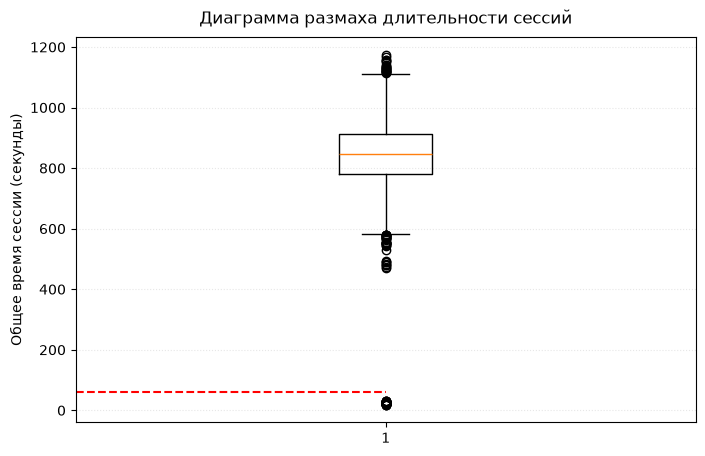

In [15]:
def total_time_count(start, end):
    return (end - start).dt.total_seconds()

total_time = total_time_count(df['start_time'], df['end_time'])

plt.figure(figsize=(8, 5))

plt.boxplot(total_time)
plt.title('Диаграмма размаха длительности сессий', fontsize=12, pad=10)
plt.ylabel('Общее время сессии (секунды)', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.3)
plt.hlines(y=60, xmin=0.5, xmax=1, linestyle='--', color='red')

plt.show()

In [16]:
session_time = (df['end_time'] - df['start_time']).dt.total_seconds()
df[session_time <= 60]

,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects
74,S200074,Новосибирск,1,8,2026-04-10 09:00:00,2026-04-10 09:00:24,4.0,0.0,1.0,3.0,...,4.0,1.0,2.0,4.0,0.0,3.0,2,desktop,1,0
360,S200359,Казань,41,5,2026-04-10 09:50:00,2026-04-10 09:50:25,3.0,0.0,3.0,2.0,...,1.0,0.0,3.0,2.0,1.0,2.0,5,desktop,1,0
465,S200464,Санкт-Петербург,9,7,2026-04-10 09:13:00,2026-04-10 09:13:24,4.0,0.0,2.0,4.0,...,4.0,0.0,3.0,4.0,0.0,3.0,1,mobile,1,0
483,S200482,Казань,14,6,2026-04-10 09:45:00,2026-04-10 09:45:20,1.0,0.0,1.0,3.0,...,2.0,1.0,1.0,2.0,0.0,1.0,3,desktop,1,0
503,S200502,Новосибирск,3,9,2026-04-10 11:35:00,2026-04-10 11:35:23,2.0,1.0,3.0,1.0,...,3.0,0.0,1.0,4.0,0.0,1.0,4,desktop,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7855,S207820,Уфа,3,10,2026-04-10 09:13:00,2026-04-10 09:13:26,1.0,1.0,3.0,4.0,...,4.0,1.0,3.0,2.0,0.0,3.0,4,desktop,1,0
7909,S207874,Екатеринбург,45,5,2026-04-10 11:39:00,2026-04-10 11:39:24,1.0,0.0,2.0,1.0,...,2.0,0.0,1.0,4.0,0.0,1.0,3,mobile,1,0
7945,S207910,спб,39,5,2026-04-10 10:26:00,2026-04-10 10:26:30,2.0,1.0,3.0,2.0,...,2.0,0.0,2.0,4.0,0.0,2.0,3,desktop,1,0
7994,S207958,Ростов-на-Дону,20,7,2026-04-10 09:04:00,2026-04-10 09:04:27,4.0,0.0,3.0,2.0,...,3.0,1.0,3.0,1.0,0.0,1.0,4,desktop,1,1


#### Выводы: 
- Обнаружены сессии продолжительностью менее минуты. Для полноценного прохождения 12 заданий такая длительность выглядит аномальной и может указывать на технические или тестовые сессии.
- В рамках проекта устанавливается фильтр по длительности сессии: исключаются прохождения короче 60 секунд.
- Порог является аналитическим допущением, а не доказательством недостоверности каждой отдельной сессии.

In [17]:
task_n_answer = [f'Task_{i}_answer' for i in range(1, 13)]
task_n_correct = [f'Task_{i}_correct' for i in range(1, 13)]
task_n_time_spent = [f'Task_{i}_time_spent' for i in range(1, 13)]

In [18]:
df[task_n_answer].isna().sum()

Task_1_answer     318
Task_2_answer     341
Task_3_answer     315
Task_4_answer     310
Task_5_answer     299
Task_6_answer     327
Task_7_answer     312
Task_8_answer     316
Task_9_answer     313
Task_10_answer    316
Task_11_answer    287
Task_12_answer    321
dtype: int64

In [19]:
df[task_n_correct].isna().sum()

Task_1_correct     318
Task_2_correct     341
Task_3_correct     315
Task_4_correct     310
Task_5_correct     299
Task_6_correct     327
Task_7_correct     312
Task_8_correct     316
Task_9_correct     313
Task_10_correct    316
Task_11_correct    287
Task_12_correct    321
dtype: int64

In [20]:
df[task_n_time_spent].isna().sum()

Task_1_time_spent     318
Task_2_time_spent     341
Task_3_time_spent     315
Task_4_time_spent     310
Task_5_time_spent     299
Task_6_time_spent     327
Task_7_time_spent     312
Task_8_time_spent     316
Task_9_time_spent     313
Task_10_time_spent    316
Task_11_time_spent    287
Task_12_time_spent    321
dtype: int64

#### Вывод: 
* Task_n_answer: заполняется 0, фиксируя отсутствие выбранного варианта;
* Task_n_correct: заполняется 0, так как попытки ответа не было;
* Task_n_time_spent: остается NaN, отражая отсутствие времени работы над задачей.

Проверка показала полное совпадение числа пропущенных значений между `Task_i_answer`, `Task_i_correct` и `Task_i_time_spent` для каждого задания.
Пропуски возникают исключительно пакетом при пропуске задания участником, без частичной потери данных.

In [21]:
for col in task_n_answer:
    print(col, sorted(df[col].dropna().unique()))

Task_1_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_2_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_3_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_4_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_5_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_6_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_7_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_8_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_9_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_10_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_11_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Task_12_answer [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]


#### Вывод: 
* Среди заполненных значений поля ответа обнаружены варианты от 1 до 4;
* Это соответствует ожидаемому диапазону вариантов ответа.

In [22]:
total_time_task = df[task_n_time_spent].sum(axis=1)

In [23]:
time_diff = total_time - total_time_task
time_diff.describe()

count    8037.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
dtype: float64

#### Вывод: 
расхождений между продолжительностью сессии и общим временем выполнения заданий нет.

In [24]:
df['total_score'].info()
print(sorted(df['total_score'].unique()))

<class 'pandas.Series'>
RangeIndex: 8037 entries, 0 to 8036
Series name: total_score
Non-Null Count  Dtype
--------------  -----
8037 non-null   int64
dtypes: int64(1)
memory usage: 62.9 KB
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


#### Вывод: 
Итоговый балл находится в диапазоне от 0 до 12, что соответствует числу заданий.

In [25]:
sum_task_n_correct = df[task_n_correct].sum(axis=1)
mismatches = (df['total_score'] != sum_task_n_correct).sum()
print(mismatches)

0


#### Вывод: 
Количество строк с несовпадением баллов: 0

In [26]:
df['device_type'].unique()

<ArrowStringArray>
['desktop', 'mobile', 'tablet']
Length: 3, dtype: str

In [27]:
df['attempts_count'].describe()

count    8037.000000
mean        1.489735
std         0.499926
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         2.000000
Name: attempts_count, dtype: float64

In [28]:
df['disconnects'].describe()

count    8037.000000
mean        0.192485
std         0.441617
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         4.000000
Name: disconnects, dtype: float64

# 2. Очистка и предобработка данных

In [29]:
df_clean = df.copy()

#### Удаление полных дубликатов строк

In [30]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

#### Нормализация названий регионов

In [31]:
region_map = {
    'мск': 'Москва', 'москва': 'Москва', 'г. Москва': 'Москва', 'Moskva': 'Москва',
    'СПб': 'Санкт-Петербург', 'спб': 'Санкт-Петербург', 'Санкт Петербург': 'Санкт-Петербург',
    'г.Казань': 'Казань', 'казань': 'Казань'
}

df_clean['region'] = df_clean['region'].str.strip().replace(region_map)

#### Удаление слишком быстро завершенных сессий.

In [32]:
session_time = (df_clean['end_time'] - df_clean['start_time']).dt.total_seconds()
df_clean = df_clean[session_time >= 60].reset_index(drop=True)

#### Заполнение пропусков

In [33]:
for col in task_n_correct:
    df_clean[col] = df_clean[col].fillna(0).astype(int)
for col in task_n_answer:
    df_clean[col] = df_clean[col].fillna(0).astype(int)

In [34]:
print(f"Итоговый размер df_clean: {df_clean.shape}")
print(f"Уникальных регионов: {df_clean['region'].nunique()}")

Итоговый размер df_clean: (7928, 46)
Уникальных регионов: 10


#### Обогащение данных

In [35]:
task_time_cols = [col for col in df_clean.columns if 'time_spent' in col]

df_clean['total_time'] = total_time_count(df_clean['start_time'], df_clean['end_time'])
df_clean['avg_task_time'] = df_clean[task_time_cols].mean(axis=1).round(2)

In [36]:
df_clean

,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects,total_time,avg_task_time
0,S200000,Краснодар,9,11,2026-04-10 11:10:00,2026-04-10 11:25:19,4,0,93.0,1,...,84.0,4,0,124.0,3,desktop,2,0,919.0,76.58
1,S200001,Ростов-на-Дону,44,9,2026-04-10 10:30:00,2026-04-10 10:44:19,3,0,105.0,2,...,73.0,4,0,63.0,6,mobile,2,0,859.0,71.58
2,S200002,Екатеринбург,44,9,2026-04-10 10:25:00,2026-04-10 10:38:33,4,1,60.0,3,...,101.0,1,1,77.0,7,mobile,1,1,813.0,73.91
3,S200003,Казань,44,11,2026-04-10 10:04:00,2026-04-10 10:18:18,1,0,58.0,1,...,100.0,3,1,86.0,5,mobile,1,0,858.0,71.50
4,S200004,Уфа,26,9,2026-04-10 10:53:00,2026-04-10 11:08:36,4,0,111.0,1,...,79.0,2,0,96.0,6,mobile,2,0,936.0,78.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7923,S207995,Казань,10,6,2026-04-10 11:11:00,2026-04-10 11:26:44,4,1,85.0,4,...,70.0,1,1,134.0,4,desktop,1,0,944.0,78.67
7924,S207996,Казань,57,11,2026-04-10 09:22:00,2026-04-10 09:35:04,2,0,68.0,1,...,58.0,4,1,70.0,7,desktop,1,0,784.0,65.33
7925,S207997,Ростов-на-Дону,10,7,2026-04-10 10:24:00,2026-04-10 10:38:08,3,0,96.0,1,...,57.0,2,1,70.0,6,desktop,1,0,848.0,70.67
7926,S207998,Новосибирск,9,8,2026-04-10 09:30:00,2026-04-10 09:45:45,4,0,94.0,1,...,105.0,3,0,58.0,7,desktop,2,0,945.0,78.75


In [37]:
df_clean.to_csv('data/olympiad_results_clean.csv', index=False, encoding='utf-8-sig')
print(f"Файл сохранён. Размер: {df_clean.shape}")

Файл сохранён. Размер: (7928, 48)


### Итоги предобработки
* Удалены 37 полных дубликатов.
* Названия регионов нормализованы; после очистки выделяется 10 регионов.
* Исключены сессии длительностью менее 60 секунд.
* Пропущенные ответы и признаки правильности заполнены нулями; отсутствие времени выполнения задания сохранено как NaN.
* Созданы производные метрики общей длительности сессии и среднего времени выполнения задания.
* После предобработки получено 7 928 записей и 46 исходных признаков. 

# 3. Исследовательский анализ данных (EDA)

### 3.1. Анализ аудитории

Среднее количество участников по регионам: 792.8 
Стандартное отклонение: 28.43


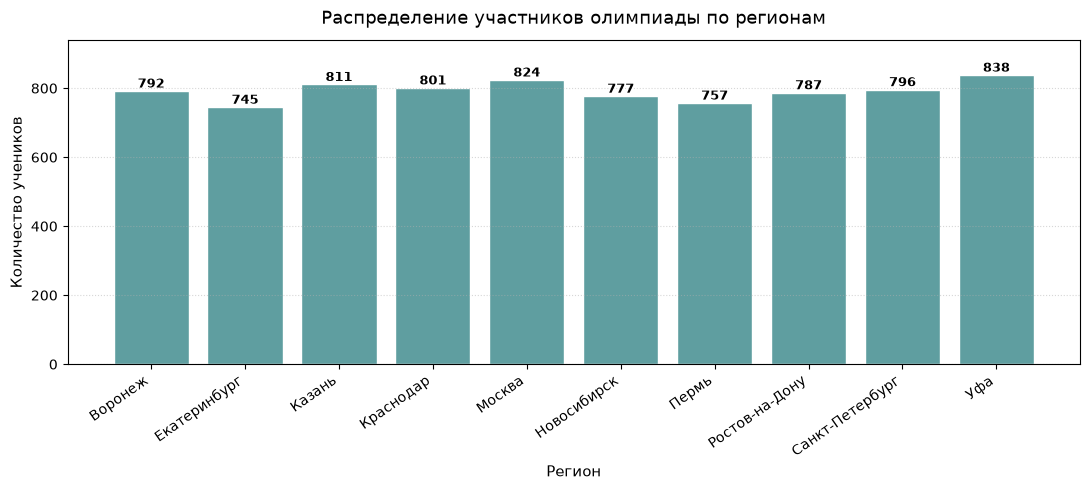

In [79]:
regions = (
    df_clean.groupby('region').agg(
        student_count=('student_id', 'nunique')
    ).reset_index()
)

print(
    f'Среднее количество участников по регионам: {regions['student_count'].mean()} \n'
    f'Стандартное отклонение: {regions['student_count'].std().round(2)}'
)

plt.figure(figsize=(11, 5))

region_bar = plt.bar(
    regions['region'],
    regions['student_count'],
    color='cadetblue',
    edgecolor='white'
)

for bar in region_bar:
    height = bar.get_height()
    plt.text(
    bar.get_x() + bar.get_width() / 2.0,
    height + 1.2,
    f'{height:.0f}',
    ha='center',
    va='bottom',
    fontsize=9,
    fontweight='bold'
    )

plt.title('Распределение участников олимпиады по регионам', fontsize=13, pad=12)
plt.xlabel('Регион', fontsize=11)
plt.ylabel('Количество учеников', fontsize=11)
plt.xticks(rotation=35, ha='right')
plt.ylim(0, regions['student_count'].max() * 1.12)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()

plt.show()

Среднее количество участников по классам: 1132.57 
Стандартное отклонение: 27.09


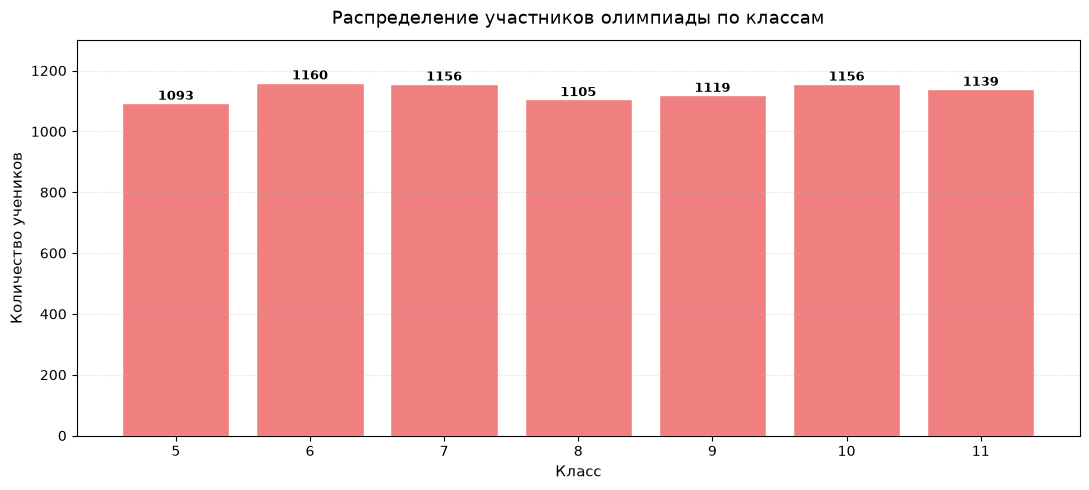

In [39]:
grades = (
    df_clean.groupby('grade').agg(
        students_count=('student_id', 'nunique')
    ).reset_index().sort_values('grade')
)

print(
    f'Среднее количество участников по классам: {grades['students_count'].mean().round(2)} \n'
    f'Стандартное отклонение: {grades['students_count'].std().round(2)}'
)

plt.figure(figsize=(11, 5))

grade_bar = plt.bar(
    grades['grade'],
    grades['students_count'],
    color='lightcoral',
    edgecolor='white'
)

for bar in grade_bar:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 1.2,
        f'{height:.0f}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )
    
plt.title('Распределение участников олимпиады по классам', fontsize=13, pad=12)
plt.xlabel('Класс', fontsize=11)
plt.ylabel('Количество учеников', fontsize=11)
plt.ylim(0, grades['students_count'].max() * 1.12)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()

plt.show()

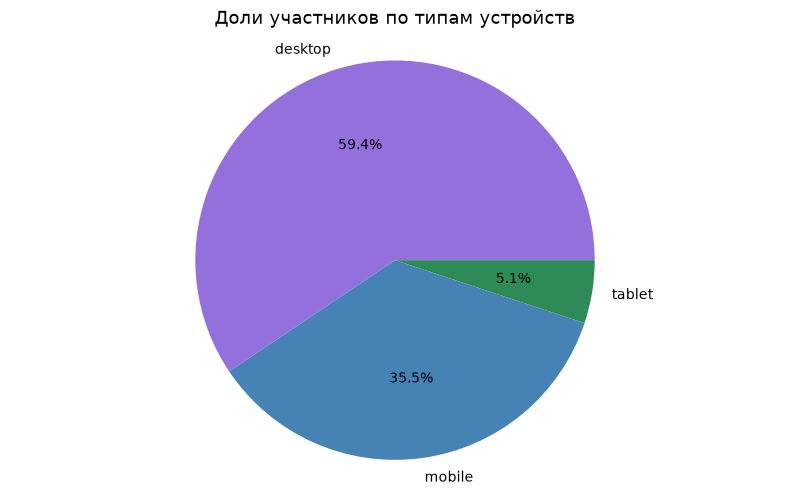

In [40]:
device = (
    df_clean.groupby('device_type').agg(
        total_devices=('device_type', 'size'),
        students_count=('student_id', 'nunique'),
    )
).reset_index()

device = device.sort_values('students_count', ascending=False)

plt.figure(figsize=(8, 5))

plt.pie(
    device['students_count'], 
    labels=device['device_type'], 
    autopct='%1.1f%%',
    colors=['mediumpurple', 'steelblue', 'seagreen']
    )

plt.title('Доли участников по типам устройств', fontsize=13, pad=12)
plt.tight_layout()
plt.axis('equal')
plt.show()

             avg_disconnects  avg_time  avg_score  avg_attempts
device_type                                                    
desktop                0.187   846.721      5.529         1.497
mobile                 0.203   848.847      5.571         1.490
tablet                 0.195   842.694      5.595         1.499


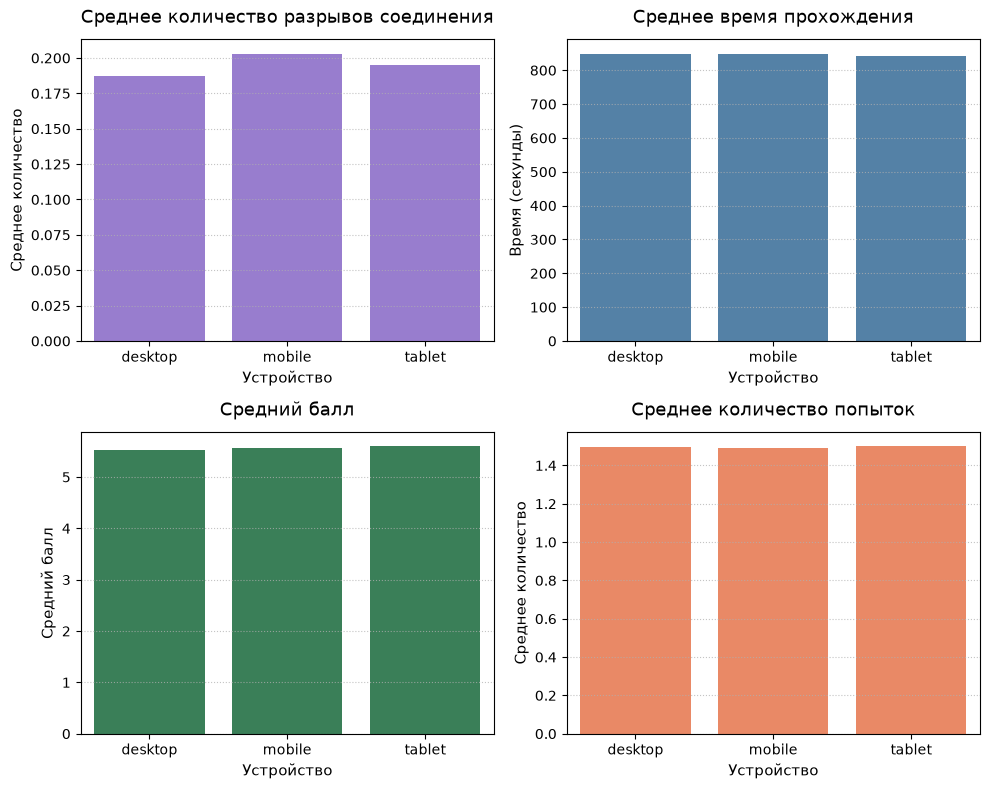

In [80]:
device_stats = (
    df_clean.groupby('device_type').agg(
        avg_disconnects=('disconnects', 'mean'),
        avg_time=('total_time', 'mean'),
        avg_score=('total_score', 'mean'),
        avg_attempts=('attempts_count', 'mean')
    )
)

cols_to_round = ['avg_disconnects', 'avg_time', 'avg_score', 'avg_attempts']
device_stats[cols_to_round] = device_stats[cols_to_round].round(3)

print(device_stats)


fig, axs = plt.subplots(nrows = 2, ncols=2, figsize=(10, 8))

sns.barplot(
    data=device_stats.reset_index(),
    x='device_type',
    y='avg_disconnects',
    color='mediumpurple',
    ax=axs[0, 0]
)

axs[0, 0].set_title('Среднее количество разрывов соединения', fontsize=13, pad=12)
axs[0, 0].set_xlabel('Устройство', fontsize=11)
axs[0, 0].set_ylabel('Среднее количество', fontsize=11)
axs[0, 0].grid(axis='y', linestyle=':', alpha=0.75)

sns.barplot(
    data=device_stats.reset_index(),
    x='device_type',
    y='avg_time',
    color='steelblue',
    ax=axs[0, 1]
)

axs[0, 1].set_title('Среднее время прохождения', fontsize=13, pad=12)
axs[0, 1].set_xlabel('Устройство', fontsize=11)
axs[0, 1].set_ylabel('Время (секунды)', fontsize=11)
axs[0, 1].grid(axis='y', linestyle=':', alpha=0.75)

sns.barplot(
    data=device_stats.reset_index(),
    x='device_type',
    y='avg_score',
    color='seagreen',
    ax=axs[1, 0]
)

axs[1, 0].set_title('Средний балл', fontsize=13, pad=12)
axs[1, 0].set_xlabel('Устройство', fontsize=11)
axs[1, 0].set_ylabel('Средний балл', fontsize=11)
axs[1, 0].grid(axis='y', linestyle=':', alpha=0.75)

sns.barplot(
    data=device_stats.reset_index(),
    x='device_type',
    y='avg_attempts',
    color='coral',
    ax=axs[1, 1]
)

axs[1, 1].set_title('Среднее количество попыток', fontsize=13, pad=12)
axs[1, 1].set_xlabel('Устройство', fontsize=11)
axs[1, 1].set_ylabel('Среднее количество', fontsize=11)
axs[1, 1].grid(axis='y', linestyle=':', alpha=0.75)

plt.tight_layout()
plt.show()

### Вывод:
**Регионы и классы близки по масштабу участия**
* Среднее число участников по регионам: 792.8 человек, отклонение от среднего в пределах ±28 участников;
* Среднее число участников по классам: 1132.6 человек, отклонение от среднего в пределах ±27 участников;
* Больше всего участников использовали пк (59.4%); мобильные телефоны и планшеты использовали меньше (35.5% и 5.1% соответственно)
**Среднее время прохождения, средний балл и количество попыток практически не зависит от устройства**;
* В среднем на одну сессию приходилось 0.19 разрывов соединения, что говорит о высокой стабильности работы платформы;
* Наиболее стабильной является десктопная версия (0.18 разрывов на одну сессию);
* Наименее стабильной является мобильная версия (0.2 разрывов на одну сессию).


### 3.2. Анализ вовлеченности аудитории

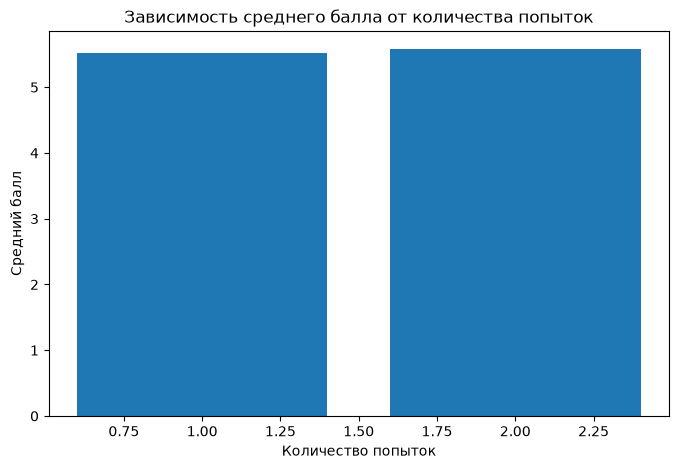

In [87]:
attempts = df_clean.groupby('attempts_count').agg(
    avg_score = ('total_score', 'mean')
)

plt.figure(figsize=(8, 5))

plt.bar(
    attempts.index,
    attempts['avg_score']
)

plt.xlabel('Количество попыток')
plt.ylabel('Средний балл')
plt.title('Зависимость среднего балла от количества попыток')

plt.show()

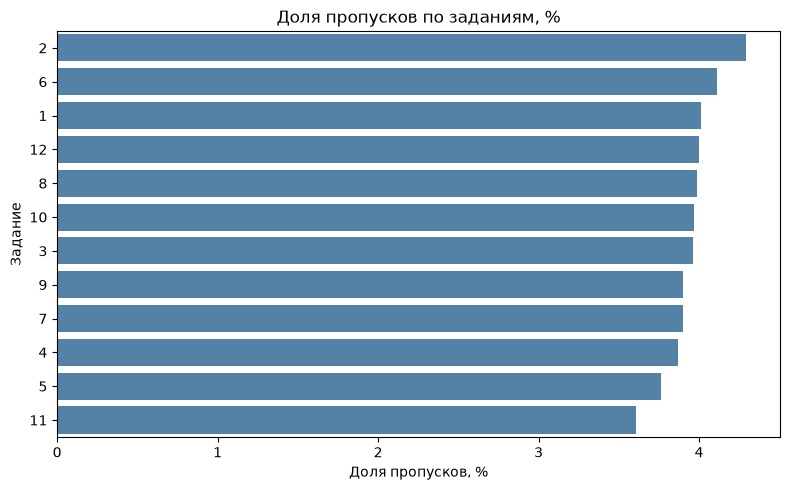

In [77]:
missed_share = (df_clean[task_n_time_spent].isna().mean().values * 100).round(2)

missed_task = pd.DataFrame({
    'Задание': [task.replace('_time_spent', '').replace('Task_', '') for task in task_n_time_spent],
    'Доля пропусков, %': missed_share
}).sort_values('Доля пропусков, %', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=missed_task,
    x='Доля пропусков, %',
    y='Задание',
    color='steelblue'
)
plt.title('Доля пропусков по заданиям, %')
plt.xlabel('Доля пропусков, %')
plt.ylabel('Задание')
plt.tight_layout()
plt.show()

Доля записей с баллом < 3: 16%
Среднее: 5.55 | Медиана: 6.0 | Мода: 5


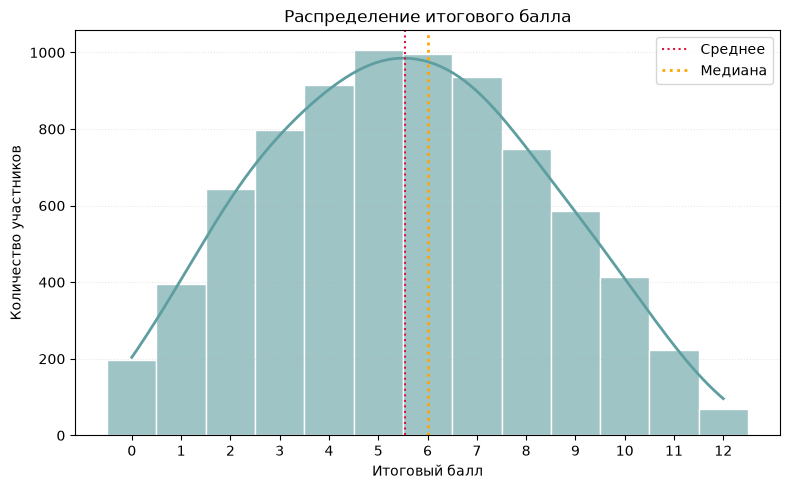

In [44]:
def score_distribution(data, title_suffix="", size_x = 8, size_y = 5):

    mean_val = data['total_score'].mean()
    median_val = data['total_score'].median()
    mode_val = data['total_score'].mode()[0]
    
    print(f"Среднее: {mean_val:.2f} | Медиана: {median_val:.1f} | Мода: {mode_val}")

    plt.figure(figsize=(size_x, size_y))
    
    sns.histplot(
        data=data,
        x='total_score',
        discrete=True,
        kde=True,
        color='cadetblue',
        edgecolor='white',
        alpha=0.6,
        kde_kws={'bw_adjust': 1.8},
        line_kws={'linewidth': 2, 'color': 'darkslategray'}
    )

    plt.axvline(
        df_clean['total_score'].mean(),
        color='crimson',
        linestyle=':',
        linewidth=1.5,
        label='Среднее'
    )
    
    plt.axvline(
        df_clean['total_score'].median(),
        color='orange',
        linestyle=':',
        linewidth=2,
        label='Медиана'
    )

    title = 'Распределение итогового балла'
    if title_suffix:
        title += f' ({title_suffix})'
    
    plt.title(title, fontsize=12)
    plt.xlabel('Итоговый балл', fontsize=10)
    plt.ylabel('Количество участников', fontsize=10)
    plt.xticks(range(0, 13))
    plt.grid(axis='y', linestyle=':', alpha=0.3)
    plt.legend(frameon=True)
    
    plt.tight_layout()
    plt.show()

share = (df_clean['total_score'] < 3).mean()
print(f'Доля участников с баллом < 3: {share:.0%}')
score_distribution(df_clean)

#### Вывод: 
* Средний балл практически не завит от количества попыток;
* Доля пропусков задания: в пределах 4%, доля участников, получивших меньше 3 баллов: 16%, что говорит о высокой вовлеченности участников;
* Наибольшее число пропусков у 2 и 6 заданий;
* Количество попыток: от 1 до 2 раз, в среднем 1.5;
**Распределение итогового балла:**
* Среднее: 5.55, Медиана: 6, Мода: 5;
* Показатели близки друг к другу, распределение данных близко к симметричному и в нём нет сильных выбросов.

### 3.3. Анализ сложности задания

In [45]:
solvability = (df_clean[task_n_correct].sum())/(len(df_clean))
missed_task = (df_clean[task_n_time_spent].isna().sum())/len(df_clean)
median_time = df_clean[task_n_time_spent].median()

task_stats = pd.DataFrame(
    {
        'task': [f'Task {i}' for i in range(1, 13)],
        'solve_rate': (solvability*100).values.round(2), 
        'missed_task': (missed_task*100).values.round(2),
        'median_time': median_time.values.round(2)
    }
)
print(task_stats)
task_stats.describe()

       task  solve_rate  missed_task  median_time
0    Task 1       28.57         4.01         64.0
1    Task 2       36.23         4.29         69.0
2    Task 3       32.56         3.96         66.0
3    Task 4       56.94         3.87         78.0
4    Task 5       61.48         3.76         81.0
5    Task 6       43.23         4.11         71.0
6    Task 7       56.46         3.90         79.0
7    Task 8       57.44         3.99         80.0
8    Task 9       30.73         3.90         66.0
9   Task 10       51.15         3.97         76.0
10  Task 11       45.03         3.61         73.0
11  Task 12       54.92         4.00         78.0


,solve_rate,missed_task,median_time
count,12.000000,12.00000,12.000000
mean,46.228333,3.94750,73.416667
std,11.781112,0.16853,6.067174
min,28.570000,3.61000,64.000000
25%,35.312500,3.89250,68.250000
50%,48.090000,3.96500,74.500000
75%,56.580000,4.00250,78.250000
max,61.480000,4.29000,81.000000


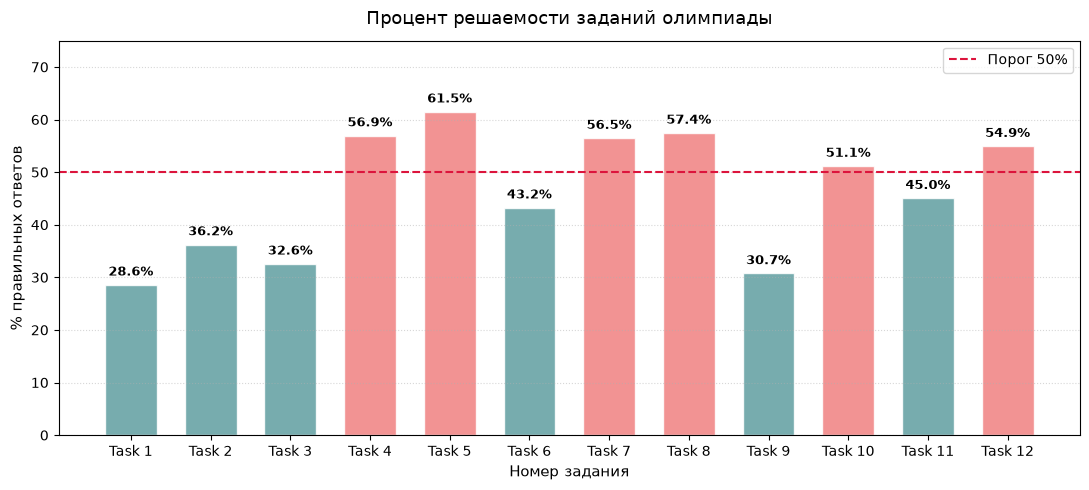

In [46]:
plt.figure(figsize=(11, 5))

diff_level = [
    'lightcoral' if val >= 50 else 'cadetblue' for val in task_stats['solve_rate']
]

task_bar = plt.bar(

    task_stats['task'],
    task_stats['solve_rate'],
    color=diff_level,
    edgecolor='white',
    alpha=0.85,
    width=0.65
)

plt.axhline(
    y=50,
    color='crimson',
    linestyle='--',
    label='Порог 50%'
)

for bar in task_bar:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 1.2,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )
    
plt.title('Процент решаемости заданий олимпиады', fontsize=13, pad=12)
plt.xlabel('Номер задания', fontsize=11)
plt.ylabel('% правильных ответов', fontsize=11)
plt.ylim(0, 75)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

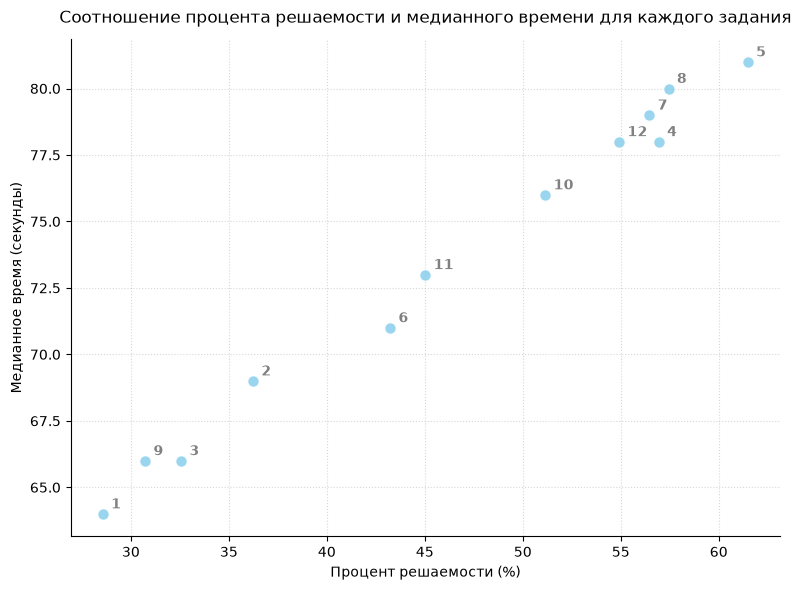

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(
    task_stats['solve_rate'],
    task_stats['median_time'],
    color='skyblue',
    s=70,
    edgecolor='white',
    alpha=0.85,
    zorder=3
)

texts = []
for _, row in task_stats.iterrows():
    task_num = row['task'].split()[-1]
    
    plt.annotate(
        task_num,
        (row['solve_rate'], row['median_time']),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=10,
        fontweight='bold',
        color='grey',
        zorder=4
    )

plt.title('Соотношение процента решаемости и медианного времени для каждого задания', fontsize=12, pad=12)
plt.xlabel('Процент решаемости (%)', fontsize=10)
plt.ylabel('Медианное время (секунды)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5, zorder=0)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

### Вывод: 
* Самым провальным оказалось стартовое задание **`Task 1` (решаемость 28.57%)**, а также **`Task 9` (30.73%)** и **`Task 3` (32.56%)**;
* Самые высокие результаты участники показали на **`Task 5` (61.48%)**, **`Task 8` (57.44%)** и **`Task 4` (56.94%)**;
* Финальное задание **`Task 12` (54.92%)** решали почти в два раза лучше, чем первое. На сложнейшие задачи (1, 3, 9) уходило меньше всего времени (медиана 64–66 с), на задачи с высокой решаемостью (5, 7, 8) тратилось максимум времени (79–81 с);
* Каждое из заданий пропускают в среднем 3.95% участников, разброс небольшой: (3.61% - 4.29%).
**Рекомендация:** Это говорит о возможной необходимости пересмотреть порядок следования задач. 

### 3.4. Региональная аналитика

#### Топ регионов по среднему баллу

In [59]:
top_regions_score = (
    df_clean.groupby('region').agg(
        avg_score=('total_score', 'mean'),
        avg_time=('total_time', 'mean')
    ).round(2).sort_values(by='avg_score', ascending=False)
)
top_regions_score

,avg_score,avg_time
region,,
Новосибирск,5.73,850.85
Москва,5.66,846.27
Екатеринбург,5.62,847.70
Ростов-на-Дону,5.60,854.02
Санкт-Петербург,5.58,845.15
Воронеж,5.50,847.21
Уфа,5.49,843.68
Казань,5.48,844.37
Краснодар,5.43,845.83


### Вывод:
* Наилучшие результаты показали участики из Новосибирска (средний балл 5.73 при среднем времени 850.9 сек) и Москвы (средний балл 5.66 при среднем времени 846.3 сек);
* Наименьшие результаты у Краснодара (средний балл 5.43) и Перми (средний балл 5.38).

### Пример регионального отчета

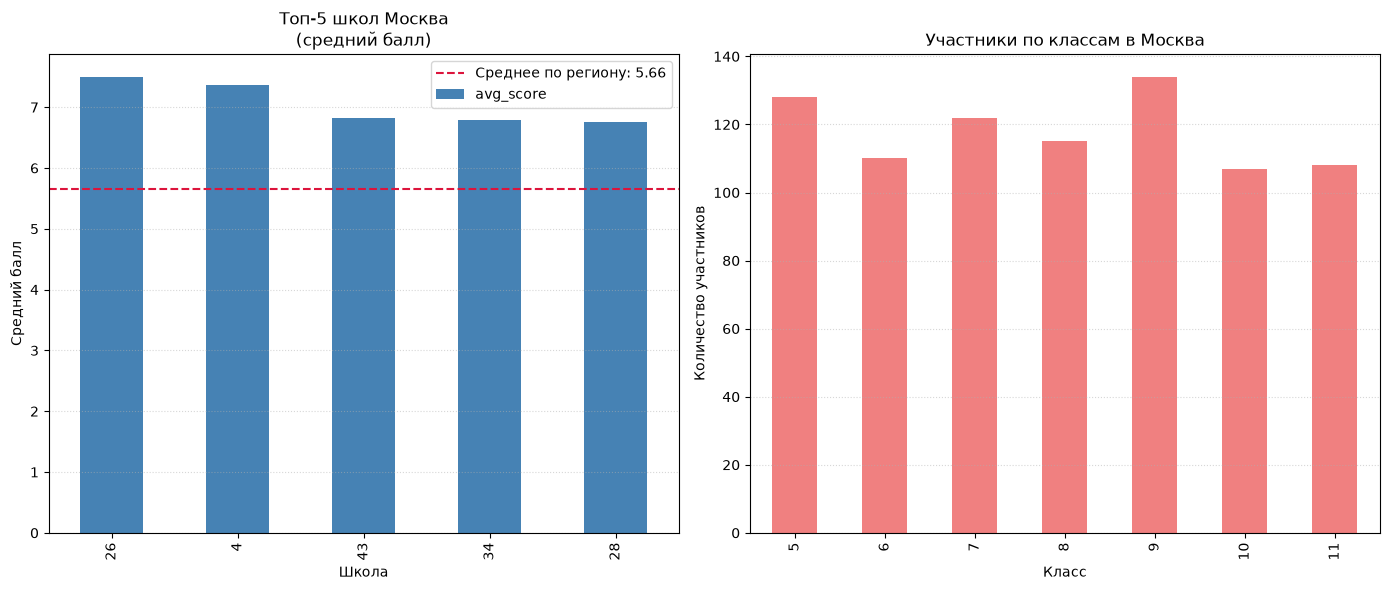


РЕГИОНАЛЬНЫЙ ОТЧЁТ: Москва

Общая статистика:
Количество участников        824.00000
Средний балл                   5.65534
Среднее время прохождения    846.27000

Топ-5 школ по среднему баллу:
               students  avg_score  avg_time
school_number                               
26                   10       7.50    838.80
4                    14       7.36    884.93
43                   12       6.83    855.92
34                   19       6.79    837.68
28                   16       6.75    880.69
None


In [78]:
def regional_report(data, region):
    
    region_df = data.loc[
        data['region'].eq(region)
    ].copy()
    if region_df.empty:
        return "Регион не найден!"

    reg_info = pd.Series({
        'Количество участников': region_df['student_id'].nunique(),
        'Средний балл': region_df['total_score'].mean(),
        'Среднее время прохождения': round((
            region_df['end_time'] -
            region_df['start_time']
        ).dt.total_seconds().mean(), 2)
    })
    
    top_schools = (
        region_df.groupby('school_number')
        .agg(
            students=('student_id', 'count'),
            avg_score=('total_score', 'mean'),
            avg_time=('total_time', 'mean')
        )
        .query('students >= 10')
        .sort_values('avg_score', ascending=False)
        .head(5)
        .round(2)
    )
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    top_schools.reset_index().plot(
        x='school_number', y='avg_score', kind='bar',
        ax=axes[0], color='steelblue', legend=False
    )

    by_grade = (
        region_df.groupby('grade')
        .agg(
            students=('student_id', 'count'),
            avg_score=('total_score', 'mean')
        )
        .round(2)
    )
    
    axes[0].set_title(f'Топ-5 школ {region}\n(средний балл)', fontsize=12)
    axes[0].set_xlabel('Школа')
    axes[0].set_ylabel('Средний балл')
    axes[0].axhline(y=reg_info['Средний балл'], color='crimson',
                    linestyle='--', label=f"Среднее по региону: {round(reg_info['Средний балл'], 2)}")
    axes[0].legend()
    axes[0].grid(axis='y', linestyle=':', alpha=0.5)

    by_grade.reset_index().plot(
        x='grade', y='students', kind='bar',
        ax=axes[1], color='lightcoral', legend=False
    )
    axes[1].set_title(f'Участники по классам в {region}', fontsize=12)
    axes[1].set_xlabel('Класс')
    axes[1].set_ylabel('Количество участников')
    axes[1].grid(axis='y', linestyle=':', alpha=0.5)

    plt.tight_layout()
    plt.show()

    print(f"\n{'='*50}")
    print(f"РЕГИОНАЛЬНЫЙ ОТЧЁТ: {region}")
    print(f"{'='*50}")
    print("\nОбщая статистика:")
    print(reg_info.to_string())
    print("\nТоп-5 школ по среднему баллу:")
    print(top_schools.to_string())


# Пример:
region_ = 'Москва'
print(regional_report(df_clean, region_))

### 3.4. Аналитика по классам

In [74]:
grade_stats = df_clean.groupby('grade').agg(
    students=('student_id', 'nunique'),
    avg_score=('total_score', 'mean'),
    median_score=('total_score', 'median'),
    std_score=('total_score', 'std'),
    avg_time=('total_time', 'mean')
).round(2)

grade_stats['weak_share'] = (
    df_clean[df_clean['total_score'] < 3]
    .groupby('grade').size()
    .div(grade_stats['students']) * 100
).round(1).fillna(0)

grade_stats['strong_share'] = (
    df_clean[df_clean['total_score'] >= 8]
    .groupby('grade').size()
    .div(grade_stats['students']) * 100
).round(1).fillna(0)

grade_stats.columns = [
    'Участников', 'Ср. балл', 'Медиана', 'Ст. откл.',
    'Ср. время (сек)', '% (<3)', '% (≥8)'
]
grade_stats

,Участников,Ср. балл,Медиана,Ст. откл.,Ср. время (сек),% (<3),% (≥8)
grade,,,,,,,
5,1093,4.50,4.0,2.74,848.54,26.5,15.4
6,1160,4.85,5.0,2.65,847.29,20.5,17.2
7,1156,5.26,5.0,2.63,846.94,17.3,20.2
8,1105,5.46,5.0,2.68,847.04,15.7,24.7
9,1119,5.91,6.0,2.74,844.75,11.9,29.8
10,1156,6.21,6.0,2.71,847.65,9.9,34.1
11,1139,6.62,7.0,2.72,848.67,7.6,38.5


### Выводы:
* Средний балл плавно растет от 4.5 (5 класс) до 6.6 (11 класс);
* Доля участников, получивших <3 баллов в 5 классе составляет 26.5%, в 6 - 20.5%. Рекомендация: для 5 и 6 классов стоит добавить более простые задания, а также усилить подготовку к олимпиадам в младших классах;
* 10-11 классы показывают высокий результат, доля получивших ≥8 баллов составила 34.1% и 38.5% соответственно, что говорит о высоком уровне подготовки и замотивированности учеников;
* В среднем, ученики всех классов тратят примерно одинаковое количество времени на задания. 

# 4. Бизнес выводы

**1. В первую очередь необходимо проверить задания с низкой решаемостью.**

Наименьшая доля правильных ответов зафиксирована в заданиях 1 (28,57%), 9 (30,73%) и 3 (32,56%). Эти результаты указывают на потенциальные точки затруднения для участников (но сами по себе не доказывают некорректность заданий).

**Рекомендация:** перед следующим запуском провести методическую экспертизу этих задач, проверить однозначность формулировок и соответствие предполагаемому уровню сложности. После доработки сравнить решаемость с результатами текущего запуска.

**2. Младшим школьникам может потребоваться дополнительная образовательная поддержка.**

Средний балл повышается с 4,50 в 5-м классе до 6,62 в 11-м. Доля участников с результатом менее 3 баллов снижается с 26,5% до 7,6%.

**Рекомендация:** разработать дополнительные материалы для участников 5–6-х классов и проверить, какие задания вызывают у них наибольшие затруднения. Решение об изменении сложности и структуры олимпиады принимать после сравнения решаемости отдельных заданий внутри классов.

**3. Региональные различия**

Средний балл варьируется от 5,38 до 5,73 из 12. При этом среднее время прохождения во всех регионах близко.

**Рекомендация:** использовать автоматизированные региональные отчёты для поиска конкретных отклонений по заданиям, классам и школам. 

**4. Поддержка версий.**

Компьютер используют 59,4% участников, мобильные устройства — 35,5%, планшеты — 5,1%. Среднее число разрывов соединения составляет около 0,19 на сессию.

**Рекомендация:** сохранить внимание к мобильной версии и отслеживать не только среднее число разрывов, но и долю сессий с техническими сбоями, связь с пропусками заданий и возможное влияние на результаты.